# K-Nearest Neighbors (KNN) and Support Vector Machines (SVM)

This notebook covers two widely used supervised classification algorithms that are often introduced together:

- **KNN** - a simple, instance-based learner that classifies a point by looking at its nearest neighbours.
- **SVM** - a margin-based learner that finds the decision boundary with the largest separation between classes.

Both algorithms are sensitive to feature scaling, so every experiment below uses a `StandardScaler`.

## Learning objectives

By the end of this notebook you will be able to:

1. Explain how KNN makes predictions and how the choice of `k` affects bias and variance.
2. Explain the maximum-margin idea behind SVM and the role of the kernel, `C`, and `gamma`.
3. Build both models with scikit-learn pipelines.
4. Evaluate classifiers with accuracy, precision, recall, F1, and a confusion matrix.
5. Visualise decision boundaries and reason about overfitting.

## 1. The ideas in one page

### KNN

For a new sample, KNN finds the `k` training points closest to it and takes a majority vote.

- Distance is usually Euclidean: $d(x, z) = \sqrt{\sum_i (x_i - z_i)^2}$.
- Small `k` -> flexible, low bias, high variance (overfitting).
- Large `k` -> smooth, high bias, low variance (underfitting).
- A common starting point is an odd `k` (to avoid ties) chosen with cross-validation.
- KNN has no real training phase, but prediction cost grows with the training set.
- Because distances are dominated by large-scale features, **scaling is mandatory**.

### SVM

SVM looks for the hyperplane that separates classes with the largest margin.

- The points closest to the boundary are the **support vectors**.
- The soft-margin parameter `C` controls the trade-off between a wide margin and training errors.
  - Small `C` -> stronger regularisation, wider margin, more bias.
  - Large `C` -> narrower margin, fits training data more closely, more variance.
- The **kernel trick** allows a linear method to learn non-linear boundaries.
  - `kernel="linear"` for linear boundaries.
  - `kernel="rbf"` for smooth non-linear boundaries; `gamma` controls the reach of each support vector.
- SVM training is often slower than KNN on large datasets, but prediction is fast.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Load and inspect the data

We use the built-in breast-cancer dataset: 569 samples, 30 numeric features, and a binary target
(malignant vs benign). Using a built-in dataset keeps the notebook fully offline and reproducible.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print("Feature matrix:", X.shape)
print("Classes:", dict(zip(data.target_names, np.bincount(y))))
X.head()

Feature matrix: (569, 30)
Classes: {'malignant': 212, 'benign': 357}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 4. Train/test split and scaling

We stratify the split so both sets keep the same class balance. The scaler is fitted **only on the
training set** to avoid data leakage.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape, "Test:", X_test_scaled.shape)

Train: (455, 30) Test: (114, 30)


## 5. KNN: choosing `k`

We train one KNN model for each odd value of `k` and compare training and test accuracy.
The gap between the two curves is a practical illustration of overfitting and underfitting.

In [4]:
k_values = list(range(1, 31, 2))
train_acc = []
test_acc = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_acc.append(model.score(X_train_scaled, y_train))
    test_acc.append(model.score(X_test_scaled, y_test))

knn_results = pd.DataFrame({
    "k": k_values,
    "train_accuracy": train_acc,
    "test_accuracy": test_acc,
})
knn_results

C:\Users\junai\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\junai\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1538, in _execute_ch

,k,train_accuracy,test_accuracy
0,1,1.000000,0.938596
1,3,0.978022,0.982456
2,5,0.973626,0.956140
3,7,0.975824,0.973684
4,9,0.973626,0.973684
5,11,0.971429,0.973684
6,13,0.971429,0.973684
7,15,0.969231,0.973684
8,17,0.962637,0.982456
9,19,0.967033,0.973684


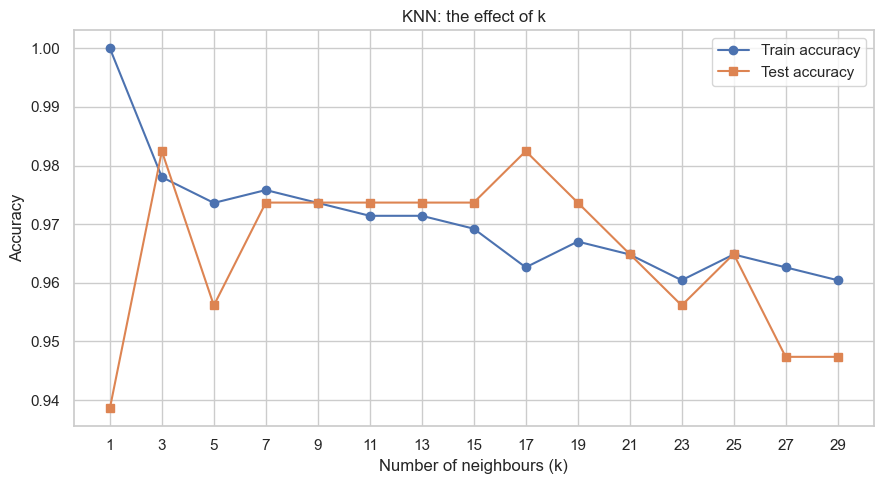

In [5]:
plt.figure(figsize=(9, 5))
plt.plot(knn_results["k"], knn_results["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(knn_results["k"], knn_results["test_accuracy"], marker="s", label="Test accuracy")
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Accuracy")
plt.title("KNN: the effect of k")
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

### Evaluate the best KNN model

In [6]:
best_k = int(knn_results.loc[knn_results["test_accuracy"].idxmax(), "k"])
print("Best k from this search:", best_k)

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=best_k)),
])
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, knn_pred), 4))
print(classification_report(y_test, knn_pred, target_names=data.target_names))

Best k from this search: 3
Accuracy: 0.9825
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



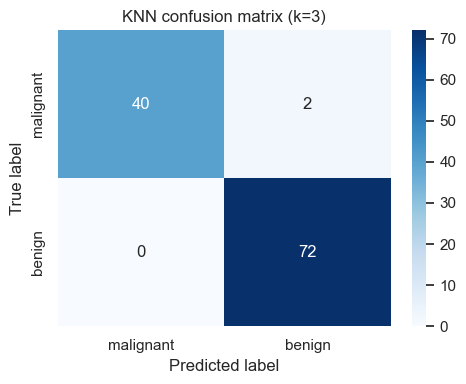

In [7]:
cm = confusion_matrix(y_test, knn_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title(f"KNN confusion matrix (k={best_k})")
plt.tight_layout()
plt.show()

## 6. SVM with linear and RBF kernels

We compare a linear SVM with an RBF SVM using the same scaled data. `C` and `gamma` are kept at
reasonable defaults for this demonstration; the next section shows a small sensitivity check.

In [8]:
svm_linear = SVC(kernel="linear", C=1.0, random_state=RANDOM_STATE)
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)

for name, model in [("SVM linear", svm_linear), ("SVM RBF", svm_rbf)]:
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    print(f"{name}: accuracy = {accuracy_score(y_test, pred):.4f}, "
          f"support vectors = {len(model.support_)}")

SVM linear: accuracy = 0.9737, support vectors = 32
SVM RBF: accuracy = 0.9825, support vectors = 97


In [9]:
svm_pred = svm_rbf.predict(X_test_scaled)
print(classification_report(y_test, svm_pred, target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### A small sensitivity check for `C`

On this dataset the classes are already well separated, so the effect of `C` is modest.
The exercise below asks you to extend this grid with different values of `gamma`.

In [10]:
sensitivity = []
for C in [0.01, 0.1, 1, 10, 100]:
    model = SVC(kernel="rbf", C=C, gamma="scale", random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    sensitivity.append({
        "C": C,
        "train_accuracy": model.score(X_train_scaled, y_train),
        "test_accuracy": model.score(X_test_scaled, y_test),
        "support_vectors": len(model.support_),
    })

pd.DataFrame(sensitivity)

,C,train_accuracy,test_accuracy,support_vectors
0,0.01,0.626374,0.631579,341
1,0.10,0.958242,0.947368,199
2,1.00,0.982418,0.982456,97
3,10.00,0.993407,0.973684,84
4,100.00,1.000000,0.947368,64


## 7. Decision boundaries in two dimensions

A 30-dimensional boundary cannot be drawn directly. To build intuition, we train the same algorithms
on the first two features and draw their decision regions. This is a teaching visual, not a
replacement for the full model.

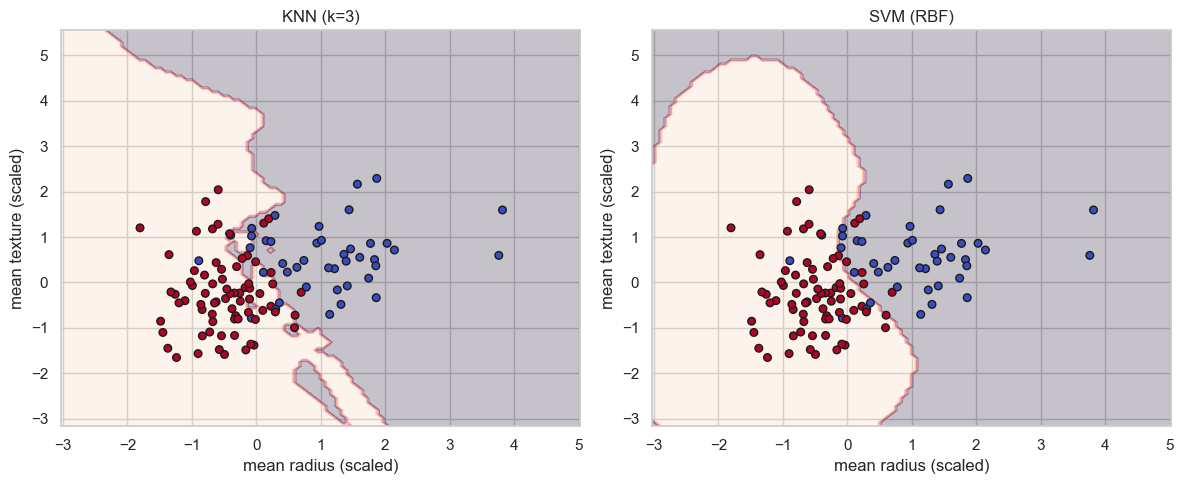

In [11]:
feature_names = ["mean radius", "mean texture"]
X2 = X[feature_names].to_numpy()
y2 = y.to_numpy()

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.20, random_state=RANDOM_STATE, stratify=y2
)

scaler_2d = StandardScaler()
X2_train_scaled = scaler_2d.fit_transform(X2_train)
X2_test_scaled = scaler_2d.transform(X2_test)

models_2d = {
    f"KNN (k={best_k})": KNeighborsClassifier(n_neighbors=best_k),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, models_2d.items()):
    model.fit(X2_train_scaled, y2_train)
    DecisionBoundaryDisplay.from_estimator(
        model, X2_train_scaled, response_method="predict", alpha=0.25, ax=ax
    )
    ax.scatter(X2_test_scaled[:, 0], X2_test_scaled[:, 1],
               c=y2_test, cmap="coolwarm", edgecolor="k", s=30)
    ax.set_title(name)
    ax.set_xlabel(feature_names[0] + " (scaled)")
    ax.set_ylabel(feature_names[1] + " (scaled)")

plt.tight_layout()
plt.show()

## 8. Summary

In [12]:
summary = pd.DataFrame({
    "Model": [f"KNN (k={best_k})", "SVM linear", "SVM RBF"],
    "Accuracy": [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_linear.predict(X_test_scaled)),
        accuracy_score(y_test, svm_rbf.predict(X_test_scaled)),
    ],
})
summary.sort_values("Accuracy", ascending=False).reset_index(drop=True)

,Model,Accuracy
0,KNN (k=3),0.982456
1,SVM RBF,0.982456
2,SVM linear,0.973684


## Key takeaways

- Always scale features before KNN and SVM.
- `k`, `C`, and `gamma` are regularisation-style knobs: tune them with cross-validation, not the test set.
- KNN is easy to explain but expensive at prediction time and weak in high dimensions.
- SVM can learn non-linear boundaries with kernels, but training cost grows with dataset size.
- Accuracy alone is not enough: inspect precision, recall, F1, and the confusion matrix.

## Exercises

1. Repeat the KNN sweep with `weights="distance"` and compare test accuracy.
2. Extend the SVM sensitivity table with `gamma` values `[0.01, 0.1, 1, 10]`.
3. Use `GridSearchCV` from scikit-learn to tune `C` and `gamma` with 5-fold cross-validation.
4. Replace the breast-cancer dataset with the two-moons dataset (`make_moons`) and compare the linear
   and RBF kernels.
5. Explain, in two sentences, why fitting a scaler on the full dataset before splitting would leak
   information.